In [1]:
import yaml
import warnings
import sys

import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as pl
import seaborn as sns
from pathlib import Path
from tqdm.auto import tqdm

# make figures paper quality
from matplotlib import rcParams
# Type 2/TrueType fonts
rcParams['pdf.fonttype'] = 42
rcParams['ps.fonttype'] = 42
# Arial font
rcParams['font.sans-serif'] = "Arial"
rcParams['font.family'] = "sans-serif"

# Remove warning, we like to live dangerously
warnings.filterwarnings("ignore")

# load functions from ../utils
sys.path.append('../utils')
from utils import annotate_essentiality

# Get config settings
with open('../configuration/config.yaml', "r") as file:
    config = yaml.load(file, Loader=yaml.FullLoader)
cell_line_dict=config['cell_lines']
cell_line_colors = config['cell_line_colors']

## Prepare data

The data objects should include:
- the actual data (lfc)
- copy number
- gene expression
- essentiality

Datasets I could use to test CNE:
- Cas9 data (Brunello)
- DepMap uncorrected Cas9 scores
- DepMap shRNA data
- our own data

In [2]:
cell_line = 'A549'  # H1299 most polyploid cell line, but p53-null. A549 is p53wt.

In [3]:
# Prepare CN annotations
depmap_cn = pd.read_csv("../resources/DepMap/DepMap_Omics_Absolute_CN_Gene_Public_24Q4_subsetted.csv", index_col=1)
depmap_cn.index = depmap_cn.index.str.replace("NCI", "")
depmap_cn = depmap_cn.loc[:, (~depmap_cn.isna()).sum(0) != 0]  # remove all-nan columns
depmap_cn = depmap_cn.iloc[:,4:].astype(int)
depmap_cn = depmap_cn.loc[:, depmap_cn.max(0) < 10] # remove all >10 outliers
depmap_cn.head()

,HNRNPA1P41,PRELID3BP1,BTNL12P,SMIM10L1,SNORD115-15,EGOT,MIPEPP2,RPL9P5,SNORD115-23,SNORD116-22,...,GPRIN2,EIF4E2,TTYH2,CD63,LPGAT1,EDEM1,TBC1D5,RPL23,GIT2,VPS9D1
cell_line_display_name,,,,,,,,,,,,,,,,,,,,,
A549,4,3,3,3,2,3,3,3,2,2,...,2,3,4,3,3,3,3,4,3,3
H1299,2,2,3,6,3,1,2,3,3,3,...,2,3,3,4,2,0,3,2,3,4
H1975,2,5,5,3,3,5,5,8,3,3,...,3,4,4,5,4,5,4,4,3,5
HT29,3,3,4,3,4,2,3,2,4,4,...,2,3,3,3,3,2,2,6,3,3


In [4]:
# Prepare GEX
depmap_gex = pd.read_csv("../resources/DepMap/DepMap_SYM101_OmicsExpressionAllGenesTPMLogp1Profile.csv", index_col=0, header=[0,1])
depmap_gex.columns = depmap_gex.columns.get_level_values(0)
depmap_gex.head()

gene_symbol,TSPAN6,TNMD,DPM1,SCYL3,C1orf112,FGR,CFH,FUCA2,GCLC,NFYA,...,ENSG00000288714,ENSG00000288717,ENSG00000288718,ENSG00000288719,ENSG00000288720,ENSG00000288721,ENSG00000288722,ENSG00000288723,ENSG00000288724,ENSG00000288725
H1975,4.308157,0.0,6.285587,2.066950,3.305971,0.014355,1.035624,6.252287,4.247168,4.496335,...,0.0,0.0,0.411426,0.014355,0.367371,0.495695,4.624101,0.000000,0.0,0.000000
HT29,3.716991,0.0,6.813012,2.807355,3.467279,0.014355,4.033863,5.449231,5.108524,4.159468,...,0.0,0.0,0.000000,0.028569,0.226509,0.464668,4.962549,0.000000,0.0,0.000000
A549,4.482203,0.0,6.398829,1.970854,4.036503,0.000000,3.775051,5.920293,6.770433,3.480265,...,0.0,0.0,0.028569,0.000000,0.150560,0.189034,5.111449,0.028569,0.0,0.042644
H1299,2.859970,0.0,6.408032,2.060047,3.765535,0.042644,0.014355,6.308885,3.843984,3.961623,...,0.0,0.0,0.028569,0.028569,0.214125,1.021480,3.234195,0.000000,0.0,0.000000


In [5]:
# SYMPHONY
counts = pd.read_csv(Path(config['TEMPDIR']) / 'SYM101_counts_corrected.csv', index_col=0)
sample_names = np.sort(counts.columns[12:])
sample_names_wo_pools = np.sort(counts.columns[15:])
pools = ['Sym-pool-1-3', 'Sym-pool-1-1', 'Sym-pool-1-2']
pools = np.sort(pools)
controls = [x for x in counts.index if 'control' in x.lower()]
counts['essential'] = annotate_essentiality(counts.Gene)
# Normalize to NT depth
norm_factor = counts.loc[controls, pools].mean(axis=1).mean() / counts.loc[controls, sample_names].mean(axis=0)
ndf = counts.loc[:, sample_names] * norm_factor
# Foldchange to Pool after seq-depth normalization based on NT depth
fc = (ndf.loc[:, sample_names].T / ndf.loc[:, pools].mean(axis=1)).T
l2fc = np.log2(fc)
l2fc[l2fc==-np.infty] = None
cell_line_cols = pd.Series({x: int(x.split('-')[1]) if 'pool' not in x else 'pool' for x in sample_names}).replace(cell_line_dict)
l2fc = l2fc.loc[:, (cell_line_cols==cell_line) & (l2fc.columns.str.contains('TP6'))]  # subset to cell line and TP6
l2fc['Gene'] = counts['Gene']
l2fc['essential'] = counts['essential']

# Add depmap copy number data
df_sym = pd.merge(l2fc, depmap_cn.loc[cell_line], left_on='Gene', right_index=True, how='left').rename(columns={cell_line: 'depmap_cn'})
df_sym['avgFC'] = df_sym.loc[:, df_sym.columns.isin(sample_names_wo_pools)].mean(axis=1, skipna=True)

# Add GEX data from depmap
df_sym = pd.merge(df_sym, depmap_gex.loc[cell_line], left_on='Gene', right_index=True, how='left').rename(columns={cell_line: 'depmap_expression'})

df_sym.to_csv(Path(config['TEMPDIR']) / 'SYM101_Linear_Model_data.csv')
df_sym.head()

,sym-03-01-TP6,sym-03-02-TP6,sym-03-03-TP6,Gene,essential,depmap_cn,avgFC,depmap_expression
unique_guide_name,,,,,,,,
AATBC_ENST00000400385_1005,0.131893,0.115107,0.145292,AATBC,unknown,2.0,0.130764,0.137504
AATBC_ENST00000400385_1562,0.247176,0.270797,0.307524,AATBC,unknown,2.0,0.275166,0.137504
AATBC_ENST00000400385_1938,0.195283,0.296882,0.347489,AATBC,unknown,2.0,0.279885,0.137504
AATBC_ENST00000400385_2713,0.023267,-0.124303,0.073560,AATBC,unknown,2.0,-0.009159,0.137504
AATBC_ENST00000400385_28,0.097635,0.150209,0.182872,AATBC,unknown,2.0,0.143572,0.137504


In [6]:
# DepMap Uncorrected scores
unc_df = pd.read_csv('../resources/DepMap/DepMap_SYM101_CRISPRGeneEffectUncorrected.csv', index_col=0).T.loc[:, cell_line]
unc_df = unc_df.to_frame().rename(columns={cell_line: 'uncorrected_score'})
unc_df['essential'] = annotate_essentiality(unc_df.index)
unc_df['Gene'] = unc_df.index

# Add depmap copy number data
unc_df = pd.merge(unc_df, depmap_cn.loc[cell_line], left_on='Gene', right_index=True, how='left').rename(columns={cell_line: 'depmap_cn'})

# Add GEX data from depmap
unc_df = pd.merge(unc_df, depmap_gex.loc[cell_line], left_on='Gene', right_index=True, how='left').rename(columns={cell_line: 'depmap_expression'})

unc_df.to_csv(Path(config['TEMPDIR']) / 'DepMap_Uncorrected_Linear_Model_data.csv')

unc_df.head()

,uncorrected_score,essential,Gene,depmap_cn,depmap_expression
A1BG,-0.147991,unknown,A1BG,3.0,2.440952
A1CF,0.133749,unknown,A1CF,3.0,0.163499
A2M,0.145885,unknown,A2M,3.0,0.000000
A2ML1,0.156504,unknown,A2ML1,3.0,0.028569
A3GALT2,0.265108,unknown,A3GALT2,2.0,0.000000


In [7]:
rnai_df = pd.read_csv("../resources/DepMap/DepMap_24Q4_CRISPR_RNAi_SYM101.csv", index_col=1)
rnai_df = rnai_df.loc[cell_line, rnai_df.columns.str.startswith("RNAi (Achilles+DRIVE+Marcotte, DEMETER2)")].to_frame()
rnai_df.index = rnai_df.index.str.split(" ").str[-1]
rnai_df = rnai_df.rename(columns={cell_line: 'rnai_score'})
rnai_df['essential'] = annotate_essentiality(rnai_df.index)
rnai_df['Gene'] = rnai_df.index

# Add depmap copy number data
rnai_df = pd.merge(rnai_df, depmap_cn.loc[cell_line], left_on='Gene', right_index=True, how='left').rename(columns={cell_line: 'depmap_cn'})

# Add GEX data from depmap
rnai_df = pd.merge(rnai_df, depmap_gex.loc[cell_line], left_on='Gene', right_index=True, how='left').rename(columns={cell_line: 'depmap_expression'})

rnai_df.to_csv(Path(config['TEMPDIR']) / 'DepMap_RNAi_Linear_Model_data.csv')

rnai_df.head()

,rnai_score,essential,Gene,depmap_cn,depmap_expression
A1BG,0.046125,unknown,A1BG,3.0,2.440952
NAT2,-0.077304,unknown,NAT2,3.0,0.070389
ADA,0.103314,unknown,ADA,3.0,4.943453
CDH2,0.050126,unknown,CDH2,2.0,5.819157
AKT3,-0.096029,unknown,AKT3,3.0,4.688740


In [8]:
# Brunello et al. data
cell_line_brunello = 'HT29'
normalization_method = 'all'  # 'NT'
# Normalize to NT depth gives really strange results and heavily unbalanced data
# Maybe the results of heave off-target effects? We end up with way more NT counts
# than I would naively expect. I will use the 'all' method for now.

# OP: https://doi.org/10.1038/s41467-018-07901-8
# https://github.com/francescojm/CRISPRcleanR/blob/master/inst/extdata/HT29-Brunello_counts.tsv
brunello_counts = pd.read_csv('../resources/Brunello_data/HT29-Brunello_counts.tsv', index_col=0, sep='\t')
sample_names = ['Brunello_plasmid', 'Brunello_HT29-rep1', 'Brunello_HT29-rep2', 'Brunello_HT29-rep3']
sample_names_wo_pools = ['Brunello_HT29-rep1', 'Brunello_HT29-rep2', 'Brunello_HT29-rep3']
controls = brunello_counts.index.str.contains('Control')
pools = ['Brunello_plasmid']

if normalization_method == 'NT':
    # Normalize to NT depth
    norm_factor = brunello_counts.loc[controls, pools].mean(axis=1).mean() / brunello_counts.loc[controls, sample_names].mean(axis=0)
elif normalization_method == 'all':
    # Normalize to all guide depth
    norm_factor = brunello_counts.loc[:, pools].mean(axis=1).mean() / brunello_counts.loc[:, sample_names].mean(axis=0)
else:
    raise ValueError("Normalization method not recognized")
ndf = brunello_counts.loc[:, sample_names] * norm_factor

# Foldchange to Pool after seq-depth normalization based on NT depth
fc = (ndf.loc[:, sample_names_wo_pools].T / ndf.loc[:, pools].mean(axis=1)).T
brunello_df = np.log2(fc)
brunello_df[brunello_df==-np.infty] = None
brunello_df['Gene'] = brunello_counts['gene']
brunello_df['essential'] = annotate_essentiality(brunello_df.Gene)

# Add depmap copy number data
brunello_df = pd.merge(brunello_df, depmap_cn.loc[cell_line], left_on='Gene', right_index=True, how='left').rename(columns={cell_line: 'depmap_cn'})

# Add GEX data from depmap
brunello_df = pd.merge(brunello_df, depmap_gex.loc[cell_line], left_on='Gene', right_index=True, how='left').rename(columns={cell_line: 'depmap_expression'})

brunello_df['avgFC'] = brunello_df.loc[:, brunello_df.columns.isin(sample_names_wo_pools)].mean(axis=1, skipna=True)

brunello_df.to_csv(Path(config['TEMPDIR']) / 'Brunello_Linear_Model_data.csv')
brunello_df.head()

,Brunello_HT29-rep1,Brunello_HT29-rep2,Brunello_HT29-rep3,Gene,essential,depmap_cn,depmap_expression,avgFC
sgRNA,,,,,,,,
A1BG_1,0.108331,-0.453604,-0.427651,A1BG,unknown,3.0,2.440952,-0.257641
A1BG_2,-0.437116,0.103967,-0.291663,A1BG,unknown,3.0,2.440952,-0.208270
A1BG_3,NaN,NaN,-0.476751,A1BG,unknown,3.0,2.440952,-0.476751
A1BG_4,0.777834,-0.134636,-0.270874,A1BG,unknown,3.0,2.440952,0.124108
A2M_5,0.096437,0.293194,0.020341,A2M,unknown,3.0,0.000000,0.136657


# Load Prepared data

In [9]:
sym_df = pd.read_csv(Path(config['TEMPDIR']) / 'SYM101_Linear_Model_data.csv', index_col=0)
brunello_df = pd.read_csv(Path(config['TEMPDIR']) / 'Brunello_Linear_Model_data.csv', index_col=0)
unc_df = pd.read_csv(Path(config['TEMPDIR']) / 'DepMap_Uncorrected_Linear_Model_data.csv', index_col=0)
rnai_df = pd.read_csv(Path(config['TEMPDIR']) / 'DepMap_RNAi_Linear_Model_data.csv', index_col=0)

In [10]:
sym_df

,sym-03-01-TP6,sym-03-02-TP6,sym-03-03-TP6,Gene,essential,depmap_cn,avgFC,depmap_expression
unique_guide_name,,,,,,,,
AATBC_ENST00000400385_1005,0.131893,0.115107,0.145292,AATBC,unknown,2.0,0.130764,0.137504
AATBC_ENST00000400385_1562,0.247176,0.270797,0.307524,AATBC,unknown,2.0,0.275166,0.137504
AATBC_ENST00000400385_1938,0.195283,0.296882,0.347489,AATBC,unknown,2.0,0.279885,0.137504
AATBC_ENST00000400385_2713,0.023267,-0.124303,0.073560,AATBC,unknown,2.0,-0.009159,0.137504
AATBC_ENST00000400385_28,0.097635,0.150209,0.182872,AATBC,unknown,2.0,0.143572,0.137504
...,...,...,...,...,...,...,...,...
ZSWIM3_ENST00000255152_164,0.224660,0.170973,0.269581,ZSWIM3,unknown,3.0,0.221738,0.847997
ZSWIM3_ENST00000255152_2431,0.332000,0.206383,0.014664,ZSWIM3,unknown,3.0,0.184349,0.847997
ZSWIM3_ENST00000255152_2528,0.059082,-0.072836,-0.158753,ZSWIM3,unknown,3.0,-0.057502,0.847997


# Plot Copy Number Effect

SYMPHONY Cas13: slope=-0.003, intercept=0.107, r_value=-0.014, p_value=0.429, std_err=0.019
slope (95%): -0.003 +/- 0.037
intercept (95%): 0.107 +/- 0.102

DepMap RNAi Scores: slope=-0.000, intercept=-0.030, r_value=-0.002, p_value=0.485, std_err=0.013
slope (95%): -0.000 +/- 0.025
intercept (95%): -0.030 +/- 0.072

DepMap Cas9 Uncorrected Scores: slope=-0.128, intercept=0.508, r_value=-0.363, p_value=0.000, std_err=0.012
slope (95%): -0.128 +/- 0.024
intercept (95%): 0.508 +/- 0.070



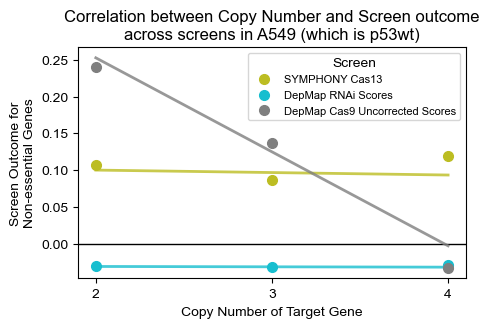

In [18]:
verbose=True
show=False
xkey='depmap_cn'
fig, ax = pl.subplots(1, 1, figsize=(5, 3))

export_data = []
for data, label, ykey, color in zip([df_sym, rnai_df, unc_df, brunello_df], 
                       ['SYMPHONY Cas13', 'DepMap RNAi Scores', 'DepMap Cas9 Uncorrected Scores'],
                       ['avgFC', 'rnai_score', 'uncorrected_score'],
                       ['tab:olive', 'tab:cyan', 'tab:gray']):
    data = data[(data[xkey]>1) & (data[xkey]<5)].copy()  # remove lost genes since we can't measure them really

    # add regression lines for each hue
    from scipy.stats import linregress
    results = {}
    hue = 'non-essential'
    x, y = data[data.essential == hue][xkey], data[data.essential == hue][ykey]
    mask = ~x.isna() & ~y.isna() & (y!=np.infty)
    res = linregress(x[mask].astype(float).values, y[mask].astype(float).values, alternative='less')
    slope, intercept, r_value, p_value, std_err = res
    
    # Calculate 95% confidence interval on slope and intercept:
    # Two-sided inverse Students t-distribution
    # p - probability, df - degrees of freedom
    from scipy.stats import t
    tinv = lambda p, df: abs(t.ppf(p/2, df))
    ts = tinv(0.05, len(x)-2)
    if hue=='non-essential' and verbose:
        print(f'{label}: slope={slope:.3f}, intercept={intercept:.3f}, r_value={r_value:.3f}, p_value={p_value:.3f}, std_err={std_err:.3f}')
        print(f"slope (95%): {res.slope:.3f} +/- {ts*res.stderr:.3f}")
        print(f"intercept (95%): {res.intercept:.3f}"
            f" +/- {ts*res.intercept_stderr:.3f}")
        print()
    results[hue] = [slope, intercept, std_err, res.intercept_stderr, r_value, p_value]
    results = pd.DataFrame(results, index=['slope', 'intercept', 'slope_stderr', 'intercept_stderr', 'r_value', 'p_value']).T

    n_entries = data.groupby(xkey).size()

    # plot means and regression lines
    means = data[(data.essential == hue) & (data[ykey]!=np.infty)].groupby(xkey).mean(numeric_only=True)
    ax.plot(means.index, means[ykey], 'o', label=label, color=color, markersize=7)
    # plot regression line
    slope, intercept, *_ = results.loc[hue]
    x = np.linspace(means.index.min(), means.index.max(), 100)
    y = x * slope + intercept
    ax.plot(x, y, linestyle='-', color=color, linewidth=2, alpha=0.8)
    
    export_data.append(data[['Gene', xkey, ykey, 'essential']].assign(screen=label))

ax.set_xlabel('Copy Number of Target Gene')
ax.set_ylabel("Screen Outcome for\nNon-essential Genes")
ax.set_xticks([2, 3, 4])
ax.set_xticklabels([2, 3, 4])
ax.set_title(f'Correlation between Copy Number and Screen outcome\nacross screens in {cell_line} (which is p53wt)')
ax.legend(title='Screen', fontsize=8, loc='upper right')
ax.axhline(0, color='black', linewidth=1, zorder=-1)
pl.savefig(f'../results/copynumber/cnv_vs_lfc_{cell_line}_boxplots_nonessential_updated.pdf', bbox_inches='tight')
pl.show()


In [23]:
export_df = pd.concat(export_data)
export_df.index.name = "transcript_id"
export_df.rename(columns={"depmap_cn": "depmap_copy_number", "avgFC": "SYM_avg_lfc"}, inplace=True)
export_df.to_csv('../results/source_tables/Fig2d_source_data.csv')

# Statistical Modelling

In [84]:
import time
from statsmodels.formula.api import mixedlm
from statsmodels.api import OLS, add_constant

### OLS regression (averaging over replicates)

Simple OLS regression model:
$$L2FC=\beta_0 + \beta_1 C + \beta_2 E + \epsilon$$

Simple OLS regression model with interaction term:
$$L2FC=\beta_0 + \beta_1 C + \beta_2 E + \beta_3 (C\cdot E) + \epsilon$$

In [85]:
def OLS_regression(data, ykey, interaction=False, verbose=False):
    # prepare data
    data = data.copy()
    X = data[['depmap_cn', 'depmap_expression']]
    X = add_constant(X)
    if interaction:
        X['interaction'] = X['depmap_cn'] * X['depmap_expression']
    y = data[ykey]
    mask = ~X.isna().any(1) & ~y.isna()
    X = X[mask].values.astype(float)
    y = y[mask].values.astype(float)
    
    # Fit OLS model
    results = OLS(y, X).fit()
    if verbose:
        print(results.summary())
        
    results_dict = dict(
        coeff_expression=results.params[2],
        coeff_copynumber=results.params[1],
        intercept=results.params[0],
        r_value=results.rsquared,
        p_value_expression=results.pvalues[2],
        p_value_copynumber=results.pvalues[1],
        std_err=results.bse[1],
        aic=results.aic,
        bic=results.bic,
        log_likelihood=results.llf,
    )
    if interaction:
        results_dict['coeff_interaction'] = results.params[3]
        results_dict['p_value_interaction'] = results.pvalues[3]
    return results_dict

In [88]:
regression_results = {}
for name, ykey, data in [
    ('SYMPHONY', 'avgFC', df_sym), 
    ('DepMap', 'uncorrected_score', unc_df),
    ('RNAi', 'rnai_score', rnai_df),
    ]:
    regression_results[(name, 'OLS')] = OLS_regression(data, ykey, interaction=False, verbose=False)
    regression_results[(name, 'OLS_interaction')] = OLS_regression(data, ykey, interaction=True, verbose=False)
ols_regression_results = pd.DataFrame(regression_results)

In [90]:
ols_regression_results.to_csv("../results/copynumber/ols_regression_results.csv")
ols_regression_results.round(4)

SYMPHONY                      DepMap                  \
                            OLS OLS_interaction         OLS OLS_interaction   
coeff_expression        -0.1243         -0.0761     -0.0778         -0.1062   
coeff_copynumber         0.0010          0.0859     -0.0806         -0.1057   
intercept                0.3232          0.0690      0.4561          0.5311   
r_value                  0.1598          0.1619      0.1986          0.2002   
p_value_expression       0.0000          0.0000      0.0000          0.0000   
p_value_copynumber       0.9467          0.0030      0.0000          0.0000   
std_err                  0.0155          0.0289      0.0040          0.0058   
aic                  13088.3404      13078.3037  18976.7159      18943.4325   
bic                  13107.8148      13104.2696  18999.9592      18974.4236   
log_likelihood       -6541.1702      -6535.1519  -9485.3580      -9467.7163   
coeff_interaction           NaN         -0.0156         NaN          0.0093   
p_value_interaction         NaN          0.0005         NaN          0.0000   

                         RNAi                  
                          OLS OLS_interaction  
coeff_expression      -0.0282         -0.0358  
coeff_copynumber       0.0159          0.0089  
intercept             -0.0569         -0.0360  
r_value                0.0772          0.0776  
p_value_expression     0.0000          0.0000  
p_value_copynumber     0.0000          0.0282  
std_err                0.0028          0.0041  
aic                  414.6159        411.1457  
bic                  436.8257        440.7588  
log_likelihood      -204.3079       -201.5729  
coeff_interaction         NaN          0.0025  
p_value_interaction       NaN          0.0194

In [91]:
# Mediation analysis
def mediation_analysis(data, ykey, verbose=False):
    
    # Step 1: Effect of depmap_cn on lfc (total effect)
    X1 = add_constant(data[['depmap_cn']])
    y1 = data[ykey]
    mask1 = ~X1.isna().any(1) & ~y1.isna()
    model1 = OLS(y1[mask1].values.astype(float), X1[mask1].values.astype(float)).fit()

    # Step 2: Effect of depmap_cn on depmap_expression (a-path)
    X2 = add_constant(data[['depmap_cn']])
    y2 = data['depmap_expression']
    mask2 = ~X2.isna().any(1) & ~y2.isna()
    model2 = OLS(y2[mask2].values.astype(float), X2[mask2].values.astype(float)).fit()

    # Step 3: Effect of depmap_expression on lfc, while controlling for depmap_cn (b-path and direct effect c')
    X3 = add_constant(data[['depmap_cn', 'depmap_expression']])
    y3 = data[ykey]
    mask3 = ~X3.isna().any(1) & ~y3.isna()
    model3 = OLS(y3[mask3].values.astype(float), X3[mask3].values.astype(float)).fit()

    # Calculate indirect effect (a*b)
    a = model2.params[1]
    b = model3.params[2]
    indirect_effect = a * b

    # Direct effect (c')
    direct_effect = model3.params[1]

    # Total effect (c)
    total_effect = model1.params[1]
    if verbose:
        print(f"Indirect effect: {indirect_effect}")
        print(f"Direct effect: {direct_effect}")
        print(f"Total effect: {total_effect}")
    return dict(indirect_effect=indirect_effect, direct_effect=direct_effect, total_effect=total_effect)


In [92]:
med_ana_results = {}
med_ana_results["SYMPHONY"] = mediation_analysis(df_sym, 'avgFC', verbose=False);
med_ana_results["DepMap"] = mediation_analysis(unc_df, 'uncorrected_score', verbose=False);
med_ana_results["RNAi"] = mediation_analysis(rnai_df, 'rnai_score', verbose=False);
med_ana_df = pd.DataFrame(med_ana_results).T

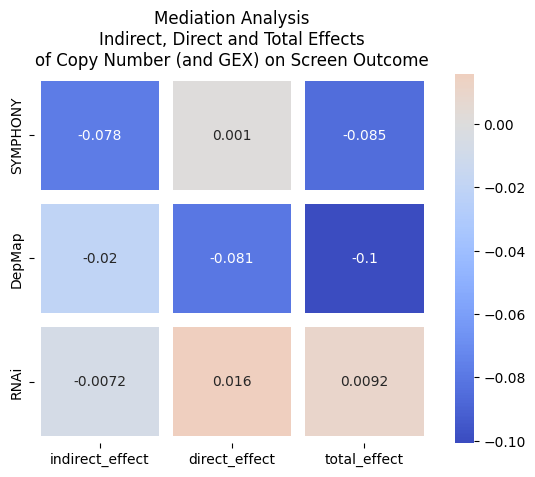

In [93]:
sns.heatmap(med_ana_df, annot=True, cmap='coolwarm', center=0, linewidths=10)
pl.title('Mediation Analysis\nIndirect, Direct and Total Effects\nof Copy Number (and GEX) on Screen Outcome')
pl.savefig(f'../results/copynumber/mediation_analysis_{cell_line}.pdf', bbox_inches='tight')
pl.show()

- The Durbin-Watson statistic (1.411) suggests some autocorrelation, which may need to be addressed.
- Conduct residual analysis to check for any patterns that might suggest model misspecification.
- Also do this analysis for the other cell lines.
- Currently I take average over replicates, can I include the replicates in the analysis somehow?

I think most of these issues can be addressed by using a proper model. I should probably try a mixed-effects model.

### Mixed-effects model

In [94]:
# Convert to long format (different samples stacked on top of each other instead of multiple columns across samples)
df_sym['essential_codes'] = df_sym.essential.astype('category').cat.codes
df_sym['unique_guide_name'] = df_sym.index
df_long = df_sym.melt(id_vars=['unique_guide_name', 'Gene', 'essential', 'depmap_cn', 'depmap_expression', 'essential_codes'], 
                  value_vars=['sym-03-01-TP6', 'sym-03-02-TP6', 'sym-03-03-TP6'], 
                  var_name='replicate', value_name='logfold_change')
df_long = df_long[df_long.isna().sum(1)==0]

In [95]:
# Prepare data, ensure formats
data = df_long[df_long.essential!='unknown'].copy()
data.depmap_expression = data.depmap_expression.astype(float)
data.depmap_cn = data.depmap_cn.astype(int)
data.replicate = data.replicate.astype('category')

In [96]:
data.shape

(5247, 8)

- fixed effects:
    - copy number
    - gene expression
- random effects
    - Genes (I expect guides targeting different genes to have varying baseline lfc)
    - Replicates (The measurements are not independent for the same replicate)
- Technically I could also add target transcript as another random effect nested below genes, but I don't think it's necessary, given that the guides are not truly isoform-specific.

So how do I put this into python code?

Let's try writing down the model:
- Data:
    - $Y_{i}^{jk}$ is the lfc of the guide $i$ targeting gene $j$ in replicate $k$
    - $C^{j}$ is the copy number of gene $j$
    - $E^{j}$ is the gene expression of gene $j$
- Coefficients:
    - $\beta_{0}$ is the intercept (fixed effect); overall baseline lfc across all genes and replicates
    - $\beta_{1}$ is the coefficient for copy number (fixed effect); average change in lfc per unit change in copy number
    - $\beta_{2}$ is the coefficient for gene expression (fixed effect); average change in lfc per unit change in gene expression
    - $u_{j}\sim N(0,\sigma^2_u)$ is the random intercept for gene $j$
    - $v_{k}\sim N(0,\sigma^2_v)$ is the random intercept for replicate $k$
    - $\epsilon_{i}^{jk}\sim N(0,\sigma^2_\epsilon)$ is the residual error

The model is then:
$$Y_{i}^{jk} = \beta_{0} + \beta_{1}C^{j} + \beta_{2}E^{j} + u_{j} + v_{k} + \epsilon_{i}^{jk}$$

Open questions:
- I should probably also include the interaction between copy number and gene expression, right?
- There is no variation in copy number or expression for guides targeting the same gene, even across replicates, since we did not measure those per replicate (and copy number would be constant anyways). Should I still include genes as random effects?
    - Yes, still makes sense. Assume you have two genes with the same CN and GEX. The guides targeting these genes will still have different baseline lfc, which is what the gene random effect captures.

In [97]:
def mixed_effect_model(data, verbose=False):
    start_time = time.time()
    # Random intercept per gene to account for differences in baseline l2fc (e.g. by biological function)
    model = mixedlm("logfold_change ~ depmap_cn + depmap_expression", # fixed effects
                    data,
                    groups=data["Gene"], # random intercept per gene
                    # re_formula="~1|replicate"  # random intercept per replicate
                    )
    # Would be nice but not possible in python:
    # Random intercept per replicate to account for technical variability across replicates
    result = model.fit()
    if verbose:
        print(result.summary())
    print("--- %s seconds ---" % (time.time() - start_time))
    return result

In [98]:
result = mixed_effect_model(data, verbose=True)

            Mixed Linear Model Regression Results
Model:             MixedLM Dependent Variable: logfold_change
No. Observations:  5247    Method:             REML          
No. Groups:        223     Scale:              0.7240        
Min. group size:   12      Log-Likelihood:     -6825.3352    
Max. group size:   63      Converged:          Yes           
Mean group size:   23.5                                      
-------------------------------------------------------------
                  Coef.  Std.Err.    z    P>|z| [0.025 0.975]
-------------------------------------------------------------
Intercept          0.288    0.121   2.382 0.017  0.051  0.525
depmap_cn          0.028    0.036   0.778 0.436 -0.043  0.099
depmap_expression -0.135    0.010 -13.180 0.000 -0.155 -0.115
Group Var          0.197    0.026                            

--- 39.55483794212341 seconds ---


In [99]:
# residual analysis
def plot_model_eval(data, result, show=True):
    with sns.axes_style('darkgrid'):
        _, axs = pl.subplots(1, 3, figsize=(6*3, 6))
    
    results_tab = data.copy()
    results_tab['fitted'] = result.fittedvalues
    results_tab['residual'] = result.resid
    
    # Plot residuals against fitted values
    ax = axs[0]
    sns.scatterplot(data=results_tab, x='fitted', y='residual', 
                    size='depmap_cn',
                    hue='essential', ax=ax,
                    palette={'essential': 'tab:red', 'non-essential': 'tab:blue'}, 
                    alpha=0.5)
    # sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
    ax.axhline(0, color='red', linestyle='--')
    ax.set_xlabel('Fitted values (L2FC)')
    ax.set_ylabel('Residuals')
    ax.set_title('Mixed LM: Residuals vs Fitted Values')
    
    # I see that there is almost not effect from replicates, but strong effect from genes
    ax = axs[1]
    random_effects = pd.concat(result.random_effects).reset_index(level=1, drop=True)
    sns.histplot(random_effects, ax=ax)
    ax.set_xlabel('Random Effect per Gene')
    ax.set_title('Distribution of Random Effects per Gene')
    
    
    # QQ-plot of residuals
    ax = axs[2]
    from statsmodels.api import qqplot
    from scipy import stats
    qqplot(results_tab['residual'], line='45', dist=stats.distributions.norm, ax=ax)
    ax.set_title('Normal Q-Q Plot of Residuals')
    if show: pl.show()

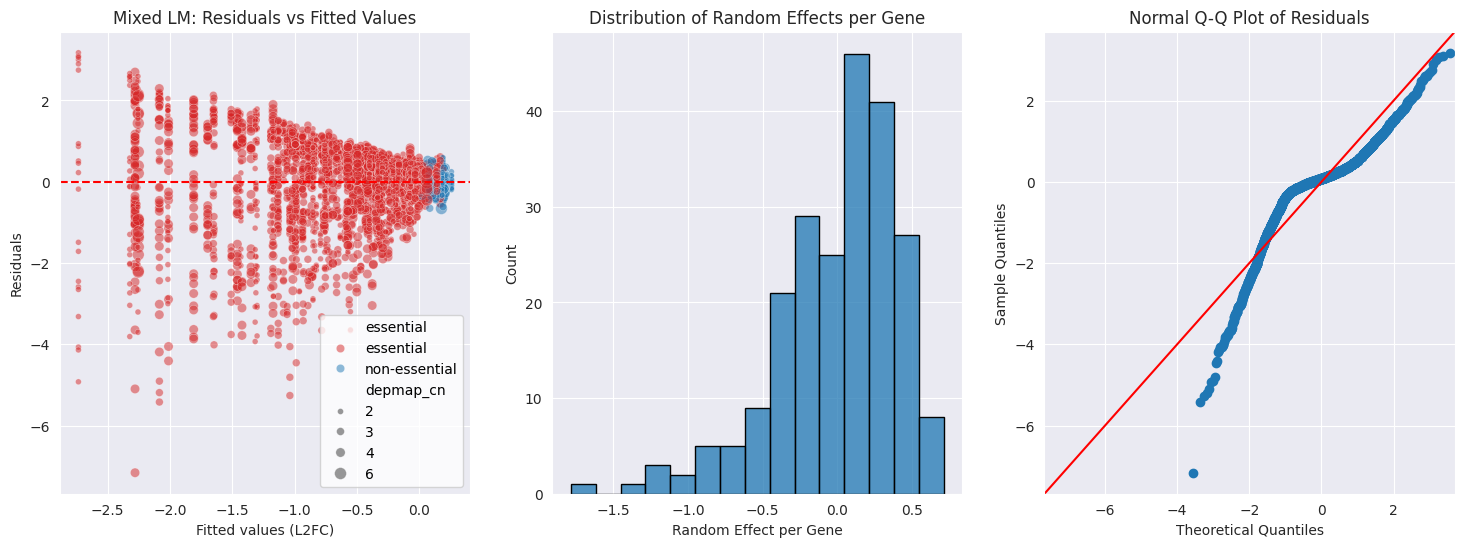

In [100]:
plot_model_eval(data, result, show=False)
pl.savefig(f'../results/copynumber/mixedlm_residuals_{cell_line}.pdf', bbox_inches='tight')
pl.show()

In [101]:
log_likelihood = result.llf  # Log-Likelihood
n_params = len(result.fe_params) + len(result.random_effects) + 1  # fixed + random effects + scale
n = len(data)

aic = 2 * n_params - 2 * log_likelihood
bic = np.log(n) * n_params - 2 * log_likelihood

print(f"AIC: {np.round(aic,0)}")
print(f"BIC: {np.round(bic,0)}")

AIC: 14105.0
BIC: 15595.0


# General Predictors of guide success

In [11]:
# Prepare CN annotations
depmap_cn = pd.read_csv("../resources/DepMap/DepMap_Omics_Absolute_CN_Gene_Public_24Q4_subsetted.csv", index_col=1)
depmap_cn.index = depmap_cn.index.str.replace("NCI", "")
depmap_cn = depmap_cn.loc[:, (~depmap_cn.isna()).sum(0) != 0]  # remove all-nan columns
depmap_cn = depmap_cn.iloc[:,4:].astype(int)
depmap_cn = depmap_cn.loc[:, depmap_cn.max(0) < 10] # remove all >10 outliers

In [12]:
# Prepare GEX
depmap_gex = pd.read_csv("../resources/DepMap/DepMap_SYM101_OmicsExpressionAllGenesTPMLogp1Profile.csv", index_col=0, header=[0,1])
depmap_gex.columns = depmap_gex.columns.get_level_values(0)

In [13]:
# Load our Data
cell_line = 'A549'  # H1299 most polyploid cell line, but p53-null. A549 is p53wt.
counts = pd.read_csv(Path(config['TEMPDIR']) / 'SYM101_counts.csv', index_col=0)
sample_names = np.sort(counts.columns[12:])
sample_names_wo_pools = np.sort(counts.columns[15:])
pools = ['Sym-pool-1-3', 'Sym-pool-1-1', 'Sym-pool-1-2']
pools = np.sort(pools)
controls = [x for x in counts.index if 'control' in x.lower()]

# annotate essential genes
counts['essential'] = annotate_essentiality(counts.Gene)

# Normalize to NT depth
norm_factor = counts.loc[controls, pools].mean(axis=1).mean() / counts.loc[controls, sample_names].mean(axis=0)
ndf = counts.loc[:, sample_names] * norm_factor

# Foldchange to Pool after seq-depth normalization based on NT depth
fc = (ndf.loc[:, sample_names].T / ndf.loc[:, pools].mean(axis=1)).T
l2fc = np.log2(fc)
l2fc[l2fc==-np.infty] = None
cell_line_cols = pd.Series({x: int(x.split('-')[1]) if 'pool' not in x else 'pool' for x in sample_names}).replace(cell_line_dict)
l2fc = l2fc.loc[:, (cell_line_cols==cell_line) & (l2fc.columns.str.contains('TP6'))]  # subset to cell line and TP6
l2fc = pd.concat([counts.iloc[:, :10], l2fc], axis=1)
l2fc['essential'] = counts['essential']

# Add depmap copy number data
df_sym = pd.merge(l2fc, depmap_cn.loc[cell_line], left_on='Gene', right_index=True, how='left').rename(columns={cell_line: 'depmap_cn'})
df_sym['avgFC'] = df_sym.loc[:, df_sym.columns.isin(sample_names_wo_pools)].mean(axis=1, skipna=True)

# Add GEX data from depmap
df_sym = pd.merge(df_sym, depmap_gex.loc[cell_line], left_on='Gene', right_index=True, how='left').rename(columns={cell_line: 'depmap_expression'})

# TODO: add isoform expression data
# Add transcript expression data (CCLE/DepMap)
# isoform_expression = pd.read_csv("../resources/DepMap/DepMap_SYM101_OmicsExpressionTranscriptsTPMLogp1Profile.csv", index_col=1).T.loc[:, cell_line]
# isoform_expression.name = 'depmap_isoform_expression'
# isoform_expression.index = isoform_expression.index.str.split('.').str[0]
# df_sym = pd.merge(df_sym, isoform_expression, left_on='Transcript_ID', right_index=True, how='left')

# Add guide alignment infos
guide_alignment_infos = pd.read_csv("../results/tables/guide_splice_junctions_summaries.csv", index_col=0)
df_sym = pd.merge(df_sym, guide_alignment_infos, left_index=True, right_index=True, how='left')

In [14]:
df_sym

,Transcript_ID,ensembl_gene_id,Gene,transcript_biotype,GuideName,GuideSeq,MatchPos,Guide_Score,Region,transcript_length,...,sym-03-03-TP6,essential,depmap_cn,avgFC,depmap_expression,is_spliced,multiple,alignment_on_gene,alignment_and_target_differ,target_in_alignments
unique_guide_name,,,,,,,,,,,,,,,,,,,,,
AATBC_ENST00000400385_1005,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA0983:983-1005,ACAGAACCCTAGGAAGCAACCTC,1005.0,0.789626,Gene_Body,4598.0,...,0.145292,unknown,2.0,0.130764,0.137504,False,False,AATBC,False,True
AATBC_ENST00000400385_1562,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA1504:1540-1562,CCAGGCCACTTGCTCCACCCTCT,1562.0,0.747814,Gene_Body,4598.0,...,0.307524,unknown,2.0,0.275166,0.137504,False,False,AATBC,False,True
AATBC_ENST00000400385_1938,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA1862:1916-1938,TGACCTCTCACCCCGCAGCCTCT,1938.0,0.747682,Gene_Body,4598.0,...,0.347489,unknown,2.0,0.279885,0.137504,False,False,AATBC,False,True
AATBC_ENST00000400385_2713,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA2601:2691-2713,CTGCCTTATAAAGATAGACCGGT,2713.0,0.870540,Gene_Body,4598.0,...,0.073560,unknown,2.0,-0.009159,0.137504,False,False,AATBC,False,True
AATBC_ENST00000400385_28,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA0006:6-28,CCGGTCTCTGCAGTCACCCTCCT,28.0,0.762563,Gene_Body,4598.0,...,0.182872,unknown,2.0,0.143572,0.137504,False,False,AATBC,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
RPS16_ENST00000251453_280,ENST00000251453,ENSG00000105193,RPS16,protein_coding,crRNA258:258-280,CCACCACCCTTTACACGGACACG,280.0,0.891826,CDS,631.0,...,-3.186822,essential,4.0,-3.198550,11.538480,False,False,RPS16,False,True
RPS16_ENST00000251453_300,ENST00000251453,ENSG00000105193,RPS16,protein_coding,crRNA278:278-300,CATAAATCTGGGCCACGTGACCA,300.0,0.892320,CDS,631.0,...,-3.485069,essential,4.0,-3.543309,11.538480,False,True,ENSG00000178715;RPS16;SPEN-AS1,True,True
RPS5_ENST00000196551_431,ENST00000196551,ENSG00000083845,RPS5,protein_coding,crRNA409:409-431,CCACTGTTGATGATGGCGTTCAC,431.0,1.006859,CDS,741.0,...,-1.565022,essential,3.0,-1.517498,10.862792,False,True,DSE;ENSG00000213791;ENSG00000233558;ENSG000002...,True,True


## Models

In [8]:
import time
from statsmodels.formula.api import mixedlm
from statsmodels.api import OLS, add_constant
from scipy.stats import zscore
def OLS_regression(data, ykey, xkeys=['depmap_cn', 'depmap_expression', 'Guide_Score', 'MatchPos', 'transcript_length', 'is_spliced', 'multiple', 'target_in_alignments'], verbose=False): # 'depmap_isoform_expression'
    # prepare data
    data = data.copy()
    X = data[xkeys]
    y = data[ykey]
    mask = ~X.isna().any(axis=1) & ~y.isna()
    X = zscore(X[mask].values.astype(float), axis=0, nan_policy='omit')  # important to zscore the data to get comparable coefficients
    y = zscore(y[mask].values.astype(float))
    
    # Fit OLS model
    X = add_constant(X)
        
    results = OLS(y, X).fit()
    if verbose:
        print(results.summary())
        
    results_dict = dict(
        intercept=results.params[0],
        r_value=results.rsquared,
        std_err=results.bse[1],
        aic=results.aic,
        bic=results.bic,
        log_likelihood=results.llf,
    )
    for i, xkey in enumerate(xkeys):
        results_dict[f'coeff_{xkey}'] = results.params[i+1]
        results_dict[f'p_value_{xkey}'] = results.pvalues[i+1]
    return results_dict

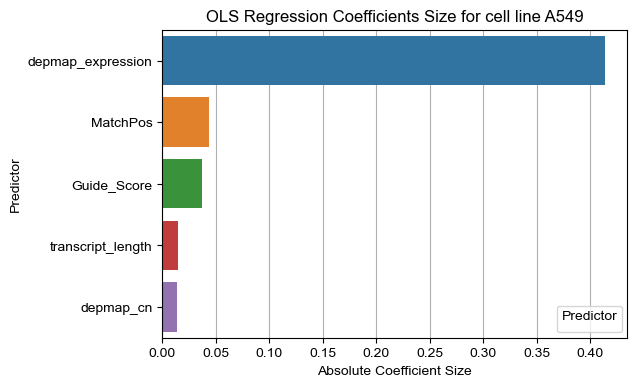

In [18]:
data = df_sym.copy()
data['Random Guide Bool'] = np.random.rand(len(data)) < 0.5
genes = df_sym.Gene.unique()
random_map = {gene: x > 0.5 for gene, x in zip(genes, np.random.rand(len(genes)) < 0.5)}
data['Random Gene Bool'] = data.Gene.map(random_map)
ykey = 'avgFC'
regression_results = OLS_regression(data, ykey, 
                                    xkeys=['depmap_cn', 'depmap_expression', 'Guide_Score', 'MatchPos', 'transcript_length'],
                                    verbose=False)
ols_regression_results = pd.Series(regression_results)

fig, ax = pl.subplots(figsize=(6, 4))
dat = ols_regression_results[ols_regression_results.index.str.startswith('coeff')].reset_index()
dat['abs'] = dat[0].abs()
dat = dat.sort_values('abs', ascending=False)
dat['sign'] = np.sign(dat[0])
sns.barplot(data = dat, y='index', x='abs', hue='index', dodge=False, ax=ax)
ax.set_title(f'OLS Regression Coefficients Size for cell line {cell_line}')
ax.set_axisbelow(True)
ax.grid(axis='x')
ax.set_xlabel('Absolute Coefficient Size')
ax.set_ylabel('Predictor')
ax.set_yticklabels([x.split('_', 1)[1] for x in dat['index']])
ax.legend(title='Predictor', fontsize=8, loc='lower right')
pl.savefig(f'../results/copynumber/ols_regression_coefficients_{cell_line}.pdf', bbox_inches='tight')
pl.show()

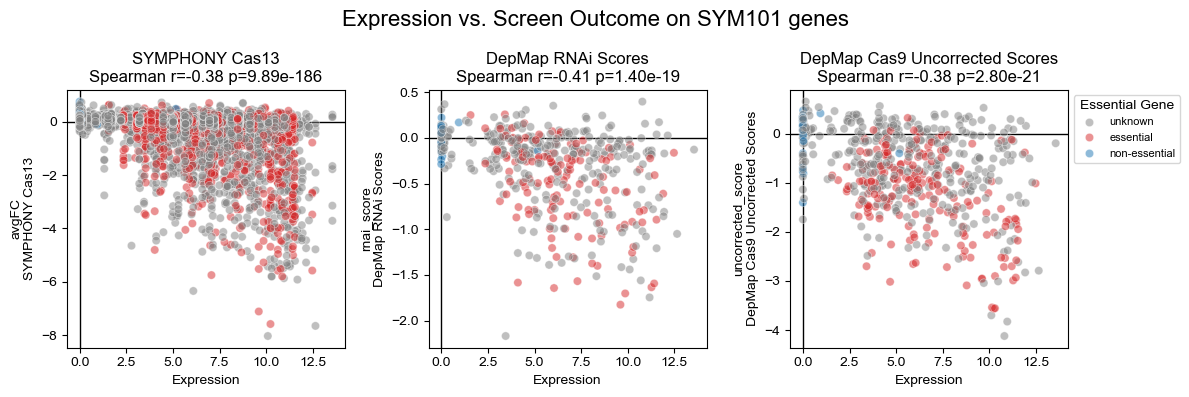

In [16]:
fig, axs = pl.subplots(1, 3, figsize=(4*3, 4))
genes = df_sym.Gene.unique()
for ax, data, label, ykey in zip(axs, 
                                 [df_sym, rnai_df, unc_df], 
                                 ['SYMPHONY Cas13', 'DepMap RNAi Scores', 'DepMap Cas9 Uncorrected Scores'],
                                 ['avgFC', 'rnai_score', 'uncorrected_score']
                                 ):
    data = data.dropna()
    data = data[data.Gene.isin(genes)].copy()
    sns.scatterplot(data=data, x='depmap_expression', y=ykey, hue='essential', 
                    palette={'essential': 'tab:red', 'non-essential': 'tab:blue', "unknown": "grey"}, 
                    alpha=0.5, ax=ax)
    from scipy.stats import spearmanr
    r, p = spearmanr(data['depmap_expression'], data[ykey])
    ax.set_xlabel('Expression')
    ax.set_ylabel(f"{ykey}\n{label}")
    ax.axhline(0, color='black', linewidth=1, zorder=-1)
    ax.axvline(0, color='black', linewidth=1, zorder=-1)
    ax.set_title(f"{label}\nSpearman r={r:.2f} p={p:.2e}")
    if ax==axs[-1]:
        ax.legend(title='Essential Gene', fontsize=8, loc='upper left', bbox_to_anchor=(1, 1))
    else:
        ax.get_legend().remove()
pl.suptitle(f'Expression vs. Screen Outcome on SYM101 genes', fontsize=16)
pl.tight_layout()
pl.savefig(f'../results/figures/expression_vs_screen_outcome_{cell_line}.pdf', bbox_inches='tight')
pl.show()